### Build A Basic Chatbot With Langgraph(GRAPH API)

In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages


In [2]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]



In [9]:
graph_builder = StateGraph(State)
graph_builder

In [29]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [13]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-20b")

In [14]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.3.15'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001E314EAA330>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001E314EAB680>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [ ]:
# llm=init_chat_model("groq:llama3-8b-8192")
# llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.3.15'}}, profile={'name': 'Llama 3 8B', 'status': 'deprecated', 'release_date': '2024-04-18', 'last_updated': '2024-04-18', 'open_weights': True, 'max_input_tokens': 8192, 'max_output_tokens': 8192, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001E3140EEF00>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001E3144A9550>, model_name='llama3-8b-8192', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [15]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [11]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph=graph_builder.compile()

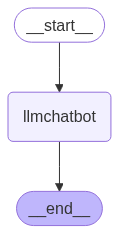

In [11]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [ ]:
response=graph.invoke({"messages":"Hi?"})

In [27]:
response["messages"][-1].content

'**The Nazis**—short for *Nationalsozialistische Deutsche Arbeiterpartei* (National Socialist German Workers’ Party)—were a far‑right, totalitarian political party that ruled Germany from 1933 to 1945 under the leadership of Adolf\u202fHitler. Here’s a brief overview:\n\n| Topic | Key Points |\n|-------|------------|\n| **Founding & Ideology** | • Founded in 1920 (originally the German Workers’ Party).<br>• Emphasized extreme nationalism, anti‑communism, antisemitism, and racial “purity” (the Aryan ideal).<br>• Promised economic revival, national unity, and a return to Germany’s pre‑World‑I stature. |\n| **Rise to Power** | • Leveraged economic hardship (Great Depression) and political instability.<br>• Gained seats in the Reichstag (parliament) in 1932; Hitler appointed Chancellor on 30\u202fJan\u202f1933.<br>• Consolidated power via the Enabling Act, the Reichstag Fire Decree, and the Night of the Long Knives. |\n| **Governance & Policies** | • Established a one‑party state with tota

In [19]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hi there! I'm doing great, thanks for asking. How about you?


In [20]:
response

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='ef95b111-4607-44b7-835e-fcc8cc65ae7b'),
  AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi". We should respond politely, perhaps ask how we can help.'}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 72, 'total_tokens': 111, 'completion_time': 0.040303803, 'completion_tokens_details': {'reasoning_tokens': 19}, 'prompt_time': 0.005319154, 'prompt_tokens_details': None, 'queue_time': 0.005779045, 'total_time': 0.045622957}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_8d13edce1d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1138c-76b3-7ef0-8e38-066a0fdb11fa-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 39, 'total_tokens': 111, 'output_token_details': {'reasoning': 19}})]}

### Chatbot With Tool

In [30]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [32]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [33]:
tools=[tool,multiply]

In [34]:
llm_with_tool=llm.bind_tools(tools)

In [35]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.3.15'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001E314EAA330>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001E314EAB680>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and

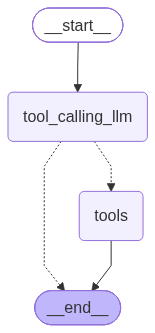

In [36]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))



In [37]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [38]:
response['messages'][-1].content

'{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.nytimes.com/2026/10/06/world/asia/south-korea-banks-hacked-ai.html", "title": "South Korea Investigates Possible Use of A.I. in Hacks on Its Banks", "content": "The president said there were signs that such models were used in recent attacks on several banks involving customer data. Police are investigating.\\n\\nAudio 1\\n\\nListen · 2:47 min\\n\\n   Share full article  \\n     \\n\\nImage 1: Two men walking in front of board showing stock market quotes.\\n\\nHana Bank was one of several financial institutions in South Korea affected by recent cyberattacks.Credit...Ahn Young-Joon/Associated Press\\n\\nImage 2: Laura ChungImage 3: Jin Yu Young\\n\\nBy Laura Chung and Jin Yu Young [...] Oct. 6, 2026, 1:18 a.m. ET\\n\\nSee more of our coverage in your search results.Encuentra más de nuestra cobertura en los resultados de búsqueda.Add The New York Times on Google Agrega

In [14]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (9hkqr0mx3)
 Call ID: 9hkqr0mx3
  Args:
    exclude_domains: []
    include_domains: []
    include_images: False
    query: recent ai news
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent ai news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.bbc.com/news/articles/cn0q2v851k9o", "title": "Amazon boss says AI will replace jobs at tech giant - BBC", "score": 0.71995544, "published_date": "Tue, 17 Jun 2025 21:31:36 GMT", "content": "Companies, especially in the tech sector, have been investing heavily in AI in recent years, spurred on by technological advances that have made it easier than ever f

In [39]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================

5 multiplied by 2 equals **10**.


In [16]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (y5rf0ar1k)
 Call ID: y5rf0ar1k
  Args:
    query: recent ai news
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent ai news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.bbc.com/news/articles/cn0q2v851k9o", "title": "Amazon boss says AI will replace jobs at tech giant - BBC", "score": 0.71995544, "published_date": "Tue, 17 Jun 2025 21:31:36 GMT", "content": "Companies, especially in the tech sector, have been investing heavily in AI in recent years, spurred on by technological advances that have made it easier than ever for chatbots to create code, images and text with

### ReAct Agent Architecture

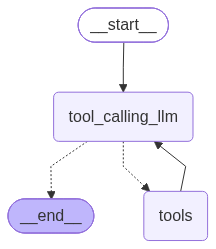

In [40]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [41]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_471c04c3-b2be-4016-bf4d-fea88a44b2bf)
 Call ID: fc_471c04c3-b2be-4016-bf4d-fea88a44b2bf
  Args:
    query: recent AI news 2026 October
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-september-2026", "title": "The latest AI news we announced in September 2026", "content": "# The latest AI news we announced in September 2026\n\nOct 02, 2026\n\n|\n12 min read\n\n   x.com\n   Facebook\n   LinkedIn\n   Mail\n   Copy link \n\nHere’s a recap of some of our biggest A

## Adding Memory In Agentic Graph

In [16]:
response=graph.invoke({"messages":"Hello my name is KRish"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is KRish
================================== Ai Message ==================================

Nice to meet you, KRish! How are you today?


In [17]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================
Tool Calls:
  multiply (xgm8j8jmw)
 Call ID: xgm8j8jmw
  Args:
    a: 1
    b: 0
================================= Tool Message =================================
Name: multiply

0
================================== Ai Message ==================================

I apologize for the mistake earlier. Since the tool call id "xgm8j8jmw" yielded 0, I will assume you are asking about your name again.

Unfortunately, I don't have any information about your name, as it's not provided in the conversation. Can you please provide more context or clarify what you mean by "my name"? I'll do my best to help.


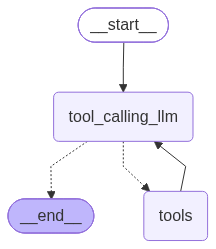

In [42]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [43]:
config={"configurable":{"thread_id":"1"}}

response=graph.invoke({"messages":"Hi my name is Krish"},config=config)

response

{'messages': [HumanMessage(content='Hi my name is Krish', additional_kwargs={}, response_metadata={}, id='11612480-2743-42b5-8bac-31e67fe4ece8'),
  AIMessage(content='Hello Krish! 👋 How can I help you today?', additional_kwargs={'reasoning_content': "We need to respond to user greeting. It's a casual conversation. Should respond friendly."}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 348, 'total_tokens': 388, 'completion_time': 0.0559689, 'completion_tokens_details': {'reasoning_tokens': 18}, 'prompt_time': 0.017975893, 'prompt_tokens_details': None, 'queue_time': 0.664425764, 'total_time': 0.073944793}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e11c8bbf69', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a113bb-1b30-7d31-9198-868849977605-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 348, 'output_tokens': 40, 'total_tokens': 388, 'output_to

In [44]:
response['messages'][-1].content

'Hello Krish! 👋 How can I help you today?'

In [45]:
response=graph.invoke({"messages":"Hey what is my name"},config=config)

print(response['messages'][-1].content)

Your name is Krish.


In [30]:
response=graph.invoke({"messages":"Hey do you remember mmy name"},config=config)

print(response['messages'][-1].content)

Your name is Krish, right?


### Streaming

In [44]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [45]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

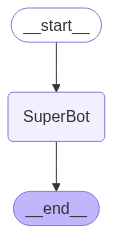

In [46]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [47]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Krish And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='4bbd93a6-5c99-476d-af9b-2542f400b2be'),
  AIMessage(content="Hi Krish! Nice to meet you! Cricket is a great sport, isn't it? Who's your favorite cricketer or team? Do you play cricket yourself or just enjoy watching and following the game?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 43, 'prompt_tokens': 20, 'total_tokens': 63, 'completion_time': 0.103689851, 'prompt_time': 0.017182506, 'queue_time': 3.3513802249999998, 'total_time': 0.120872357}, 'model_name': 'llama3-8b-8192', 'system_fingerprint': 'fp_8dc6ecaf8e', 'finish_reason': 'stop', 'logprobs': None}, id='run--46e8c88b-782a-438f-9ccc-58ab8668c0bf-0', usage_metadata={'input_tokens': 20, 'output_tokens': 43, 'total_tokens': 63})]}

### Streaming 
Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- **values** : This streams the full state of the graph after each node is called.
- **updates** : This streams updates to the state of the graph after each node is called.

In [ ]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content="Nice to meet you, Krish! It's great to hear that you like cricket! What's your favorite team or player in cricket?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 28, 'prompt_tokens': 20, 'total_tokens': 48, 'completion_time': 0.067597787, 'prompt_time': 0.017155746, 'queue_time': 3.961062715, 'total_time': 0.084753533}, 'model_name': 'llama3-8b-8192', 'system_fingerprint': 'fp_8dc6ecaf8e', 'finish_reason': 'stop', 'logprobs': None}, id='run--dd517fd5-951c-4ba1-9af4-e5eddab1c545-0', usage_metadata={'input_tokens': 20, 'output_tokens': 28, 'total_tokens': 48})]}}


In [49]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='2bdefe18-5571-41a9-9c62-59f9b739b6b6'), AIMessage(content="Nice to meet you, Krish! It's great to hear that you like cricket! What's your favorite team or player in cricket?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 28, 'prompt_tokens': 20, 'total_tokens': 48, 'completion_time': 0.067597787, 'prompt_time': 0.017155746, 'queue_time': 3.961062715, 'total_time': 0.084753533}, 'model_name': 'llama3-8b-8192', 'system_fingerprint': 'fp_8dc6ecaf8e', 'finish_reason': 'stop', 'logprobs': None}, id='run--dd517fd5-951c-4ba1-9af4-e5eddab1c545-0', usage_metadata={'input_tokens': 20, 'output_tokens': 28, 'total_tokens': 48}), HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='12985285-9873-4723-82c7-3864b7f001e4')]}
{'messages': [HumanMessage(content='Hi,My name is Krish And I lik

In [50]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content="Hello Krish! Nice to meet you! It's great to know that you like cricket! Which team do you support?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 20, 'total_tokens': 45, 'completion_time': 0.041678799, 'prompt_time': 0.017140167, 'queue_time': 5.561800282, 'total_time': 0.058818966}, 'model_name': 'llama3-8b-8192', 'system_fingerprint': 'fp_8dc6ecaf8e', 'finish_reason': 'stop', 'logprobs': None}, id='run--e14c0aff-5759-4df1-9ec3-def7a3a150dd-0', usage_metadata={'input_tokens': 20, 'output_tokens': 25, 'total_tokens': 45})]}}


In [51]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='28871637-a931-4c6d-a84b-5219d4aaf9c5'), AIMessage(content="Hello Krish! Nice to meet you! It's great to know that you like cricket! Which team do you support?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 20, 'total_tokens': 45, 'completion_time': 0.041678799, 'prompt_time': 0.017140167, 'queue_time': 5.561800282, 'total_time': 0.058818966}, 'model_name': 'llama3-8b-8192', 'system_fingerprint': 'fp_8dc6ecaf8e', 'finish_reason': 'stop', 'logprobs': None}, id='run--e14c0aff-5759-4df1-9ec3-def7a3a150dd-0', usage_metadata={'input_tokens': 20, 'output_tokens': 25, 'total_tokens': 45}), HumanMessage(content='I also like football', additional_kwargs={}, response_metadata={}, id='cdc89c65-01b1-4ccf-ab6a-48aed71fefd4')]}
{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={},

In [52]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': 'fc9179e8-7f2a-40ea-86d8-80d86b0ab3b6', 'metadata': {'thread_id': '5'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='5cbc8727-5339-4a8a-9d63-09267608e1af')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '8108e5d5-e6eb-44a0-8057-41b3e38e8eef', 'metadata': {'thread_id': '5', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:81dc6040-44c3-d3b6-96a8-292b5d7a3caa'}, 'parent_ids': ['fc9179e8-7f2a-40ea-86d8-80d86b0ab3b6']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [[HumanMessage(content='Hi My name is Krish and I like to pla